# Use GAM diagnostics to improve a model

Diagnostics are most useful when they lead to a specific modeling change. We will examine examples with insufficient basis capacity, a missing interaction, and correlated predictors, then check what changes after refitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng = np.random.default_rng(104)
def fit(formula, data):
    return GAM(formula=formula, optimize_smoothing=True, smoothing_method="reml").fit(data)
def rmse(model, data):
    return mean_squared_error(data.y, model.predict(data))**.5
results = []

## Increase insufficient basis capacity

Both fits retain the same x and z terms and use the same rows. Only the x basis dimension changes. Compare the actual k diagnostic with the curve and residuals; a particular diagnostic realization need not flag every misspecification.

In [2]:
data = pd.DataFrame({"x": rng.uniform(0,1,600), "z": rng.uniform(0,1,600)})
data["y"] = np.sin(10*np.pi*data.x) + .4*data.z + rng.normal(0,.2,len(data))
train, test = train_test_split(data,test_size=.25,random_state=104)
small = fit("y ~ s(x, bs='cr', k=4) + s(z, bs='cr', k=8)", train)
large = fit("y ~ s(x, bs='cr', k=24) + s(z, bs='cr', k=8)", train)
pd.concat({"Small basis":small.k_check(n_rep=40,seed=104),"Larger basis":large.k_check(n_rep=40,seed=104)},names=["Model","Term"]).reset_index().style.hide(axis="index").format(precision=3)

Model,Term,k_prime,edf,k_index,p_value
Small basis,s(x),3,2.825,0.099,0.000
Small basis,s(z),7,1.001,1.062,0.900
Larger basis,s(x),23,22.401,1.097,0.975
Larger basis,s(z),7,1.477,1.078,0.875


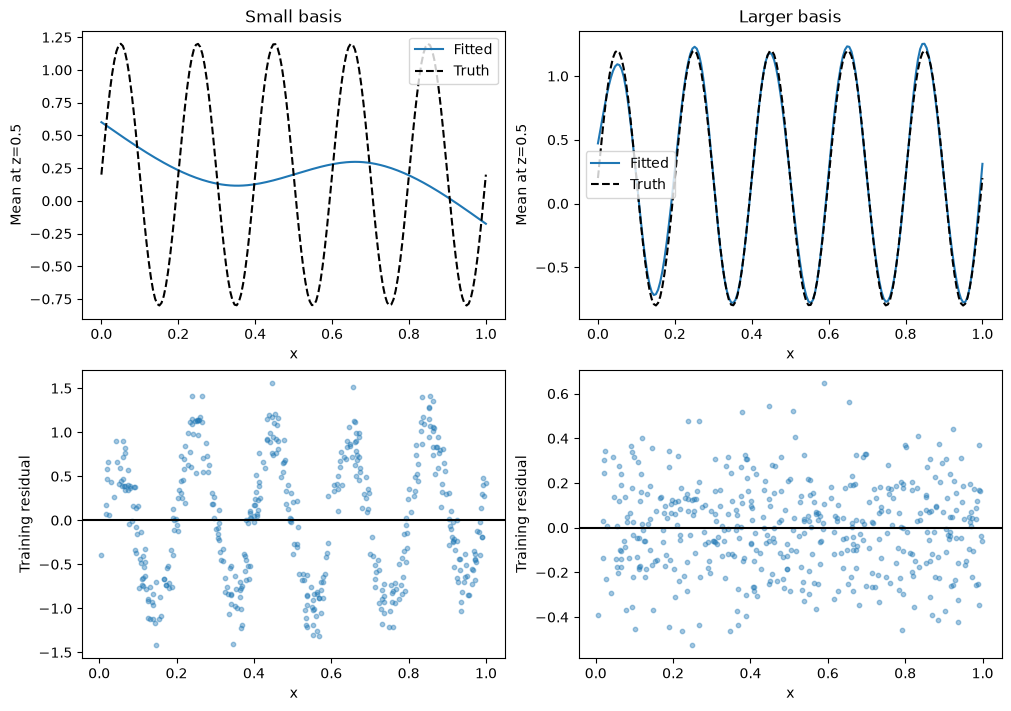

In [3]:
grid = pd.DataFrame({"x":np.linspace(0,1,180),"z":.5})
figure, axes = plt.subplots(2,2,figsize=(10,7),constrained_layout=True)
for column,(name,model) in enumerate([("Small basis",small),("Larger basis",large)]):
    axes[0,column].plot(grid.x,model.predict(grid),label="Fitted")
    axes[0,column].plot(grid.x,np.sin(10*np.pi*grid.x)+.2,"k--",label="Truth")
    axes[0,column].set(title=name,xlabel="x",ylabel="Mean at z=0.5")
    axes[0,column].legend()
    axes[1,column].scatter(train.x,train.y-model.predict(train),s=10,alpha=.4)
    axes[1,column].axhline(0,color="black")
    axes[1,column].set(xlabel="x",ylabel="Training residual")
    results.append({"Case":"Basis capacity","Model":name,"Test RMSE":rmse(model,test)})
plt.show()
plt.close(figure)

## Add a missing interaction

Main effects cannot capture the product x*z. Inspecting the validation residual pattern motivates adding `ti(x,z)`; test responses remain outside this decision.

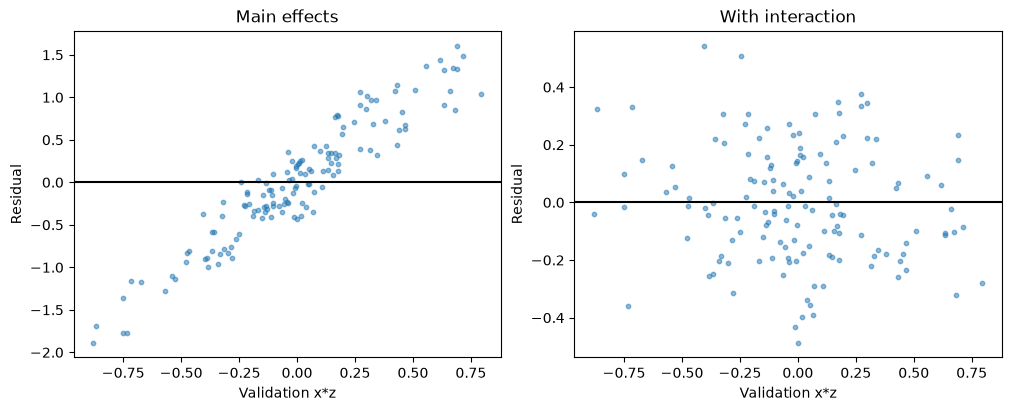

In [4]:
joint = pd.DataFrame(rng.uniform(-1,1,(700,2)),columns=["x","z"])
joint["y"] = np.sin(3*joint.x)+.3*joint.z+2*joint.x*joint.z+rng.normal(0,.2,len(joint))
development, joint_test = train_test_split(joint,test_size=.2,random_state=105)
joint_train, validation = train_test_split(development,test_size=.25,random_state=106)
main = fit("y ~ s(x, bs='cr', k=10) + s(z, bs='cr', k=10)",joint_train)
interaction = fit("y ~ s(x, bs='cr', k=10) + s(z, bs='cr', k=10) + ti(x,z,bs=c('cr','cr'),k=c(7,7))",joint_train)
figure,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for axis,(name,model) in zip(axes,[("Main effects",main),("With interaction",interaction)]):
    axis.scatter(validation.x*validation.z,validation.y-model.predict(validation),s=10,alpha=.5)
    axis.axhline(0,color="black")
    axis.set(title=name,xlabel="Validation x*z",ylabel="Residual")
    results.append({"Case":"Missing interaction","Model":name,"Test RMSE":rmse(model,joint_test)})
plt.show()
plt.close(figure)

## Inspect concurvity and effect stability

Correlated inputs may predict well while their separate contributions vary between fits. Concurvity summarizes dependence among fitted term spaces; it does not itself select which scientific explanation is correct.

In [5]:
correlated = pd.DataFrame({"x":rng.uniform(-1,1,500)})
correlated["z"] = correlated.x + rng.normal(0,.035,len(correlated))
correlated["y"] = np.sin(3*correlated.x) + rng.normal(0,.2,len(correlated))
cor_train, cor_test = train_test_split(correlated,test_size=.25,random_state=107)
formula="y ~ s(x, bs='cr', k=10) + s(z, bs='cr', k=10)"
reference = fit(formula,cor_train)
concurvity = reference.concurvity(full=True)
pd.DataFrame(concurvity["values"], index=concurvity["measure_names"], columns=concurvity["labels"]).style.format("{:.3f}")

,para,"s(x, bs='cr', k=10)","s(z, bs='cr', k=10)"
worst,0.000,0.997,0.997
observed,0.000,0.992,0.979
estimate,0.000,0.930,0.933


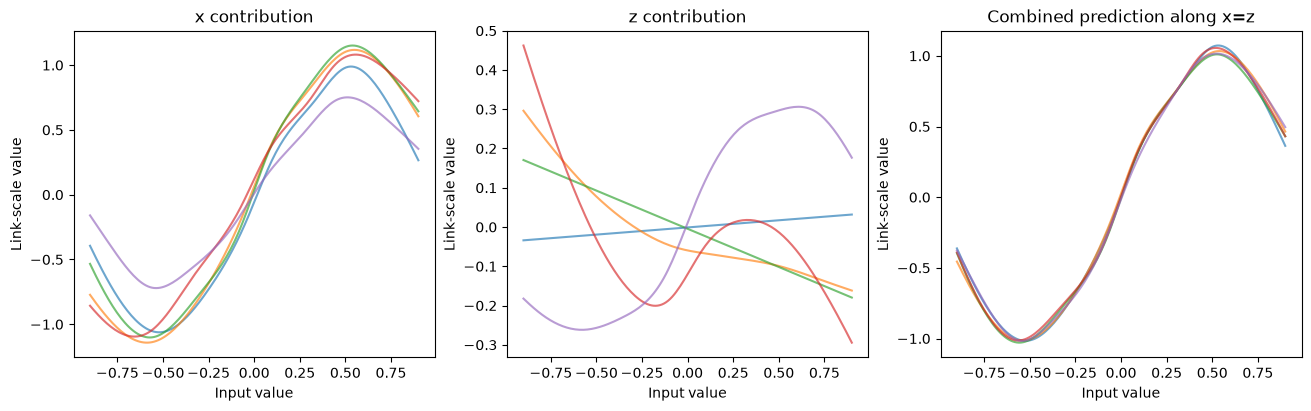

Case,Model,Test RMSE
Basis capacity,Small basis,0.775
Basis capacity,Larger basis,0.212
Missing interaction,Main effects,0.715
Missing interaction,With interaction,0.202
Correlated inputs,Bootstrap 1,0.194
Correlated inputs,Bootstrap 2,0.194
Correlated inputs,Bootstrap 3,0.196
Correlated inputs,Bootstrap 4,0.194
Correlated inputs,Bootstrap 5,0.195


In [6]:
figure,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
probe=pd.DataFrame({"x":np.linspace(-.9,.9,160),"z":np.linspace(-.9,.9,160)})
for repeat in range(5):
    sample=cor_train.sample(frac=1,replace=True,random_state=200+repeat)
    model=fit(formula,sample)
    terms=np.asarray(model.predict(probe,type="terms"))
    for i in range(2):
        axes[i].plot(probe.x,terms[:,i],alpha=.65)
    axes[2].plot(probe.x,model.predict(probe),alpha=.65)
    results.append({"Case":"Correlated inputs","Model":f"Bootstrap {repeat+1}","Test RMSE":rmse(model,cor_test)})
for axis,title in zip(axes,["x contribution","z contribution","Combined prediction along x=z"]):
    axis.set(title=title,xlabel="Input value",ylabel="Link-scale value")
plt.show()
plt.close(figure)
pd.DataFrame(results).style.hide(axis="index").format({"Test RMSE":"{:.3f}"})

The first case changes capacity, the second changes the additive structure, and the third examines ambiguity rather than promising a mechanical fix. Compare the displayed diagnostics and test results before drawing a conclusion for any one case.

Increasing x capacity reduces test RMSE from 0.775 to 0.212, and adding the interaction reduces it from 0.715 to 0.202 in the second case. The correlated-input fits retain similar test RMSE around 0.194–0.196; compare that predictive stability with the separate contribution curves.